In [82]:
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS
import numpy as np

In [36]:
df_raw = pd.read_csv('../data/usa_00003.csv')
exposure_scores = pd.read_csv('../data/final_exposure.csv')

df_raw = df_raw[(df_raw['OCC'] != 0) & (df_raw['OCC'].notna()) & df_raw['EMPSTAT'] == 1]

In [37]:
# CPS occupation
OCC_COL = 'OCC'
# CPS age
AGE_COL = 'AGE'
# Young/Entry Workers Column
Y_COL = '18_25'
# CPS weight  
WEIGHT_COL = 'WTFINL'                  
# Scores occupation       
INDEX_OCC_COL = 'CPS Code'
# All score columns
INDEX_COLS = ['alpha', 'beta', 'gamma']

In [38]:
print(df_raw['OCC'].nunique())
print(df_raw['OCC'].shape[0])

529
11406215


In [64]:
# Convert both OCC and CPS Code to string columns
df_raw[OCC_COL] = df_raw[OCC_COL].astype(float).astype(int).astype(str)
exposure_scores[INDEX_OCC_COL] = exposure_scores[INDEX_OCC_COL].astype(float).astype(int).astype(str)

In [65]:
# Merge exposure scores onto the dataset
df = df_raw.merge(exposure_scores,
                     left_on="OCC",
                     right_on=INDEX_OCC_COL,
                     how='left',
                     indicator=True)

failed = df['_merge'] == "left_only"
failed_to_merge = df[failed]

# 16 occupation codes did not merge
# They are residuals (All Other) or Military occupations (9840)
# Onet does not track them so they are being dropped
# https://www.onetcenter.org/dl_files/Taxonomy2019_Summary.pdf
# See citation 4 on page 10

assert failed_to_merge['OCC'].nunique() == 16, "Some rows did not merge or somehow not in ONET codes merged"

df = df.drop(columns=["CPS Code", "CPS Title", "_merge"])[~failed]


In [66]:
df['t'] = df['YEAR'] - 2022
df['y_18_25'] = df[AGE_COL].between(18, 25)
df['y_20_24'] = df[AGE_COL].between(20, 24)
df['y_22_25'] = df[AGE_COL].between(22, 25)

In [67]:
y_cols = ['y_18_25', 'y_20_24', 'y_22_25']

agg_dict = {
    'N': (AGE_COL, 'size'),
    **{col: (col, 'sum') for col in y_cols},
    **{col: (col, 'first') for col in INDEX_COLS},
}
df_grouped = df.groupby([OCC_COL, 't'], as_index=False).agg(**agg_dict)

In [68]:
print(df_grouped['N'].describe())

for col in y_cols:
    print(df_grouped[col].describe())

count     3078.000000
mean      3646.799220
std       6581.825278
min         90.000000
25%        507.000000
50%       1228.000000
75%       3669.000000
max      57484.000000
Name: N, dtype: float64
count     3078.000000
mean       472.151722
std       1252.168199
min          0.000000
25%         41.000000
50%        109.000000
75%        349.750000
max      16495.000000
Name: y_18_25, dtype: float64
count    3078.000000
mean      294.846654
std       723.329703
min         0.000000
25%        27.000000
50%        73.000000
75%       239.500000
max      8441.000000
Name: y_20_24, dtype: float64
count    3078.000000
mean      236.980182
std       495.127916
min         0.000000
25%        27.000000
50%        70.000000
75%       214.000000
max      4804.000000
Name: y_22_25, dtype: float64


In [69]:
for col in y_cols: 
    low = df_grouped[col] == 0
    print(f'{col}==================')
    print(df_grouped[low]['OCC'].unique())
    print(df_grouped[low]['OCC'].nunique())


y_18_25==================
<StringArray>
['3040', '3100', '3120', '3256', '3261']
Length: 5, dtype: str
5
y_20_24==================
<StringArray>
['1821', '1822', '3010', '3040', '3100', '3120', '3250', '3256', '3258',
 '3261', '3270']
Length: 11, dtype: str
11
y_22_25==================
<StringArray>
['3040', '3100', '3120', '3256', '3261']
Length: 5, dtype: str
5


In [70]:
print(df_grouped.columns)

Index(['OCC', 't', 'N', 'y_18_25', 'y_20_24', 'y_22_25', 'alpha', 'beta',
       'gamma'],
      dtype='str')


In [71]:
panel = df_grouped

In [72]:
for col in y_cols:
    panel[f'Share_{col}'] = panel[col] / panel['N']
    print(panel[f'Share_{col}'].describe())

count    3078.000000
mean        0.119100
std         0.096799
min         0.000000
25%         0.055377
50%         0.096659
75%         0.144788
max         0.810942
Name: Share_y_18_25, dtype: float64
count    3078.000000
mean        0.077501
std         0.060200
min         0.000000
25%         0.036461
50%         0.065311
75%         0.098656
max         0.640582
Name: Share_y_20_24, dtype: float64
count    3078.000000
mean        0.065870
std         0.037499
min         0.000000
25%         0.040323
50%         0.061029
75%         0.084215
max         0.272090
Name: Share_y_22_25, dtype: float64


In [73]:
panel["beta_q"] = pd.qcut(panel["beta"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
indicators = pd.get_dummies(panel["beta_q"], dtype=int)
panel = panel.join(indicators)

map = {
    "Q1": 1,
    "Q2": 2,
    "Q3": 3,
    "Q4": 4,
    "Q5": 5
}

panel["beta_q"] = panel["beta_q"].map(map)

In [74]:
print(panel['beta_q'].value_counts())

beta_q
1    624
4    618
2    612
3    612
5    612
Name: count, dtype: int64


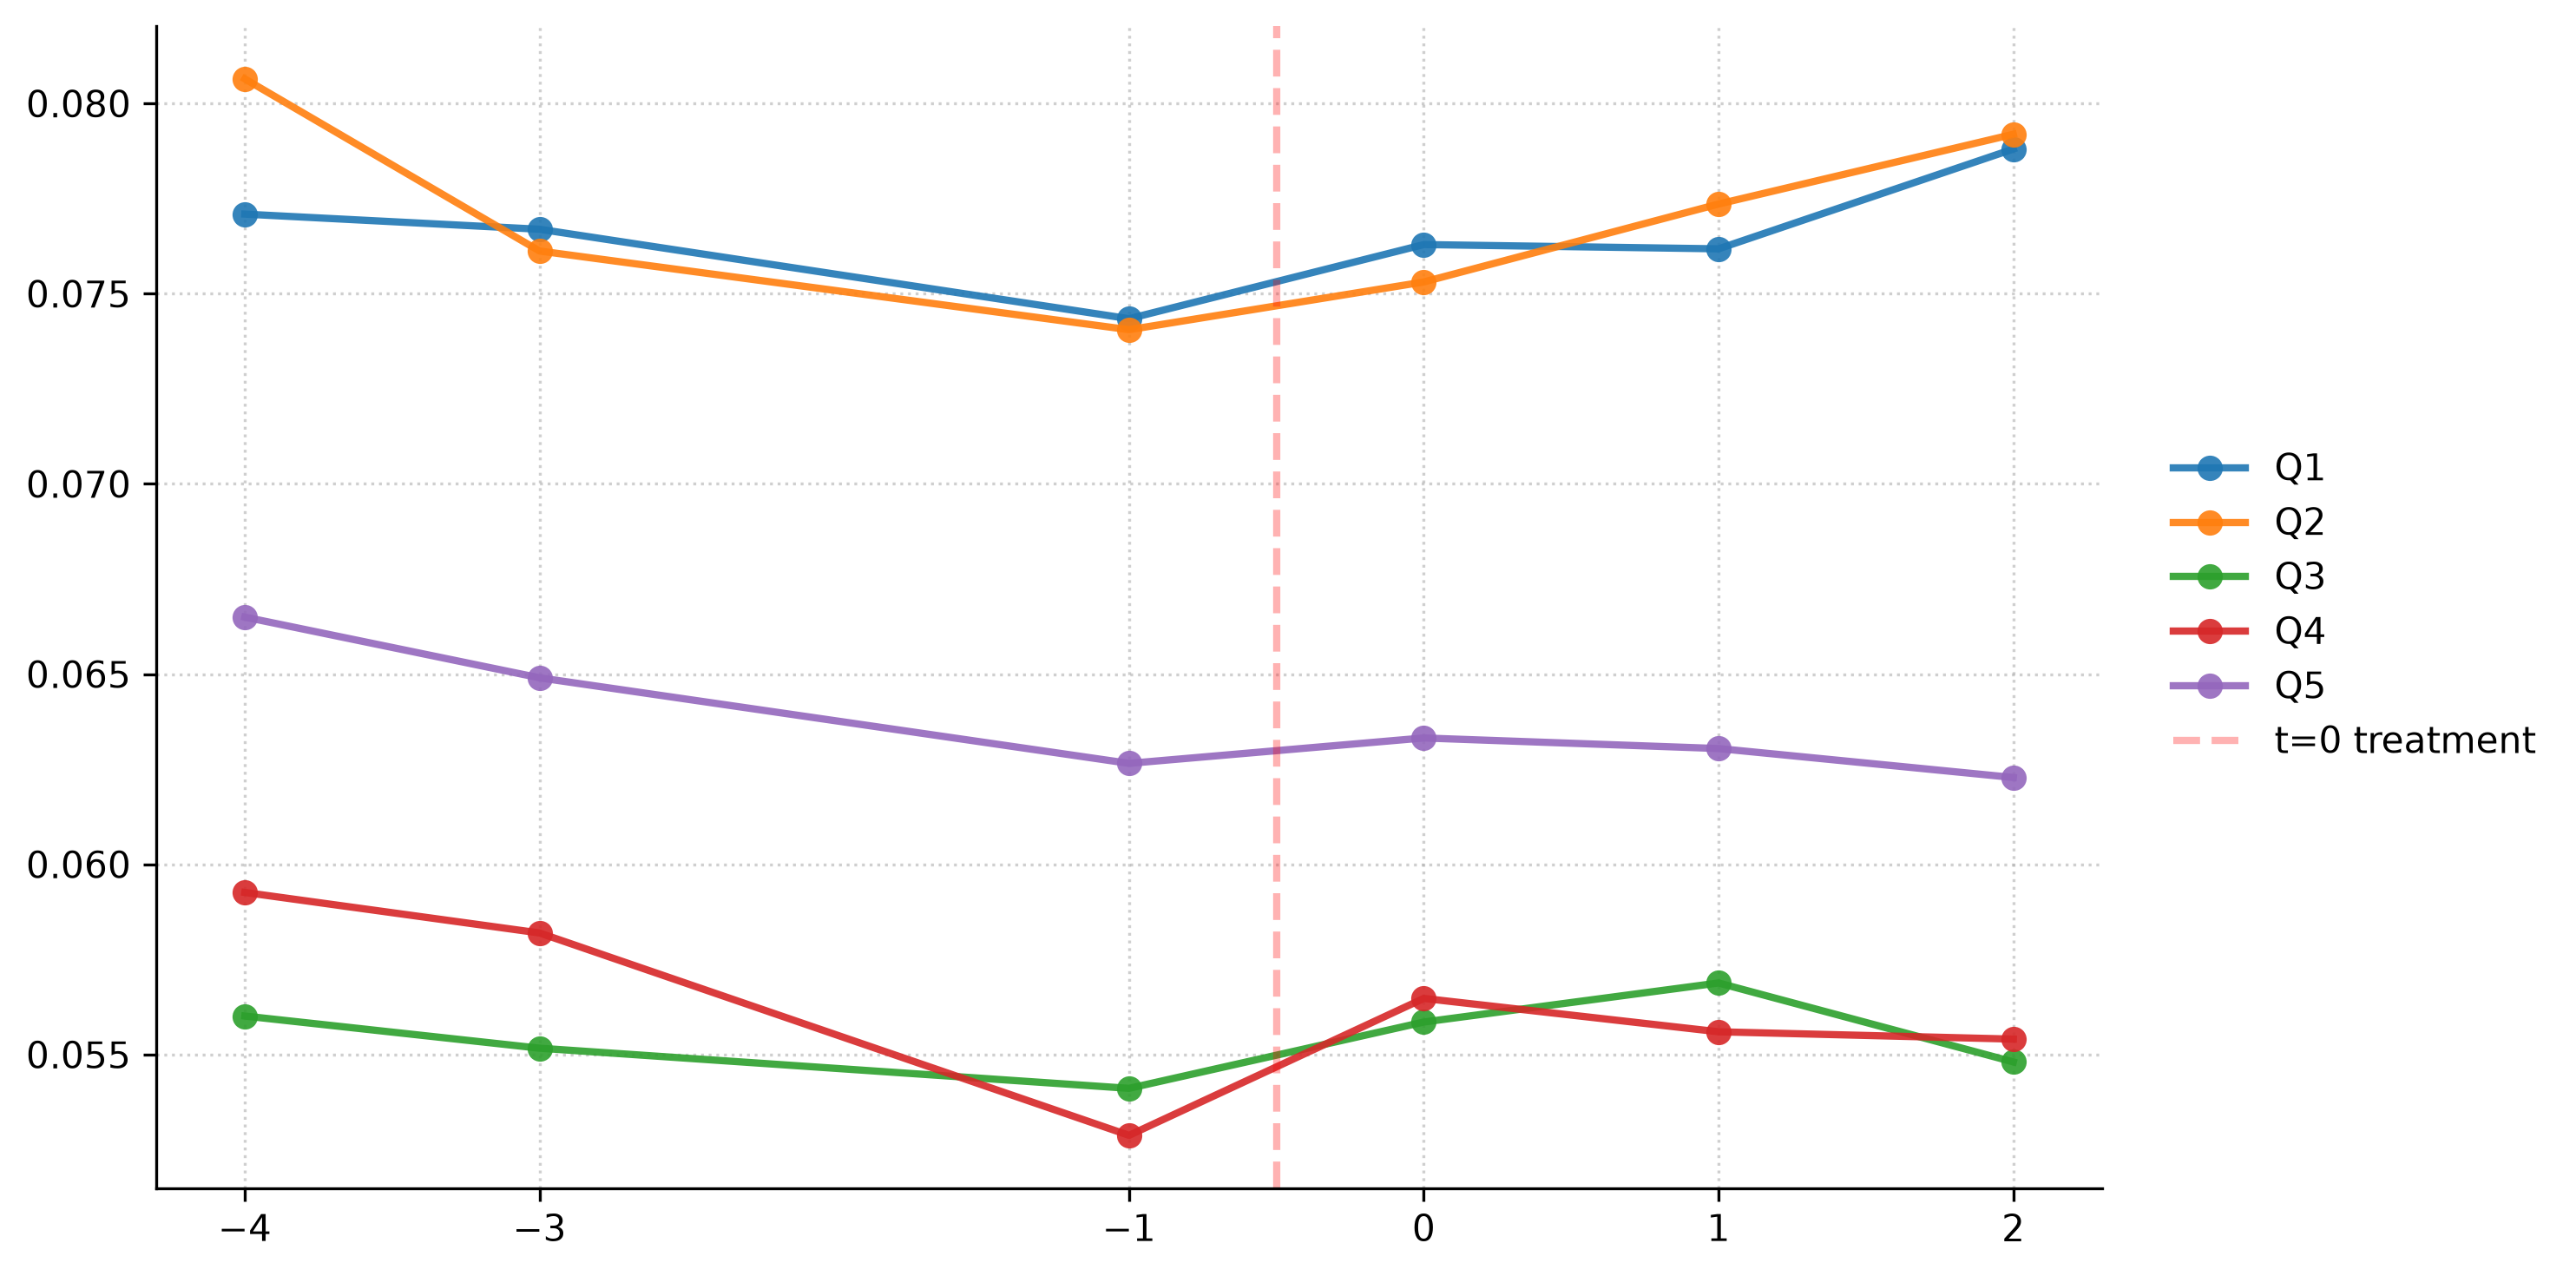

In [76]:
current_col = 'Share_y_22_25'

grouped = panel.groupby(['t', 'beta_q'])[current_col].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

labels = {1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}

for quintile, data in grouped.groupby('beta_q'):
    ax.plot(
        data['t'], 
        data[current_col], 
        label=labels[quintile],
        linewidth=2,
        marker='o',             # Adds point markers along line
        markersize=7,
        markeredgecolor='none', # Removes dark border around markers
        alpha=0.9
    )
    
ax.set_xticks(panel['t'].unique())
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.axvline(x=-0.5, color='r', linestyle='--', linewidth=2, alpha=0.3, label="t=0 treatment")

ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5))

ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()


In [77]:
print(panel.columns)

Index(['OCC', 't', 'N', 'y_18_25', 'y_20_24', 'y_22_25', 'alpha', 'beta',
       'gamma', 'Share_y_18_25', 'Share_y_20_24', 'Share_y_22_25', 'beta_q',
       'Q1', 'Q2', 'Q3', 'Q4', 'Q5'],
      dtype='str')


In [78]:
print(panel["beta_q"].value_counts())

beta_q
1    624
4    618
2    612
3    612
5    612
Name: count, dtype: int64


Index(['OCC', 'N', 'y_18_25', 'y_20_24', 'y_22_25', 'alpha', 'beta', 'gamma',
       'Share_y_18_25', 'Share_y_20_24', 'Share_y_22_25', 'beta_q', 'Q1', 'Q2',
       'Q3', 'Q4', 'Q5', 't_-4', 't_-3', 't_0', 't_1', 't_2'],
      dtype='str')
EVENT STUDY FORMULA: Share_y_22_25 ~ Q2:Q("t_-4") + Q2:Q("t_-3") + Q2:Q("t_0") + Q2:Q("t_1") + Q2:Q("t_2") + EntityEffects + TimeEffects ------------------------------
Index(['OCC', 'N', 'y_18_25', 'y_20_24', 'y_22_25', 'alpha', 'beta', 'gamma',
       'Share_y_18_25', 'Share_y_20_24', 'Share_y_22_25', 'beta_q', 'Q1', 'Q2',
       'Q3', 'Q4', 'Q5', 't_-4', 't_-3', 't_0', 't_1', 't_2'],
      dtype='str')
EVENT STUDY FORMULA: Share_y_22_25 ~ Q3:Q("t_-4") + Q3:Q("t_-3") + Q3:Q("t_0") + Q3:Q("t_1") + Q3:Q("t_2") + EntityEffects + TimeEffects ------------------------------
Index(['OCC', 'N', 'y_18_25', 'y_20_24', 'y_22_25', 'alpha', 'beta', 'gamma',
       'Share_y_18_25', 'Share_y_20_24', 'Share_y_22_25', 'beta_q', 'Q1', 'Q2',
       'Q3', 'Q4', 'Q5', '

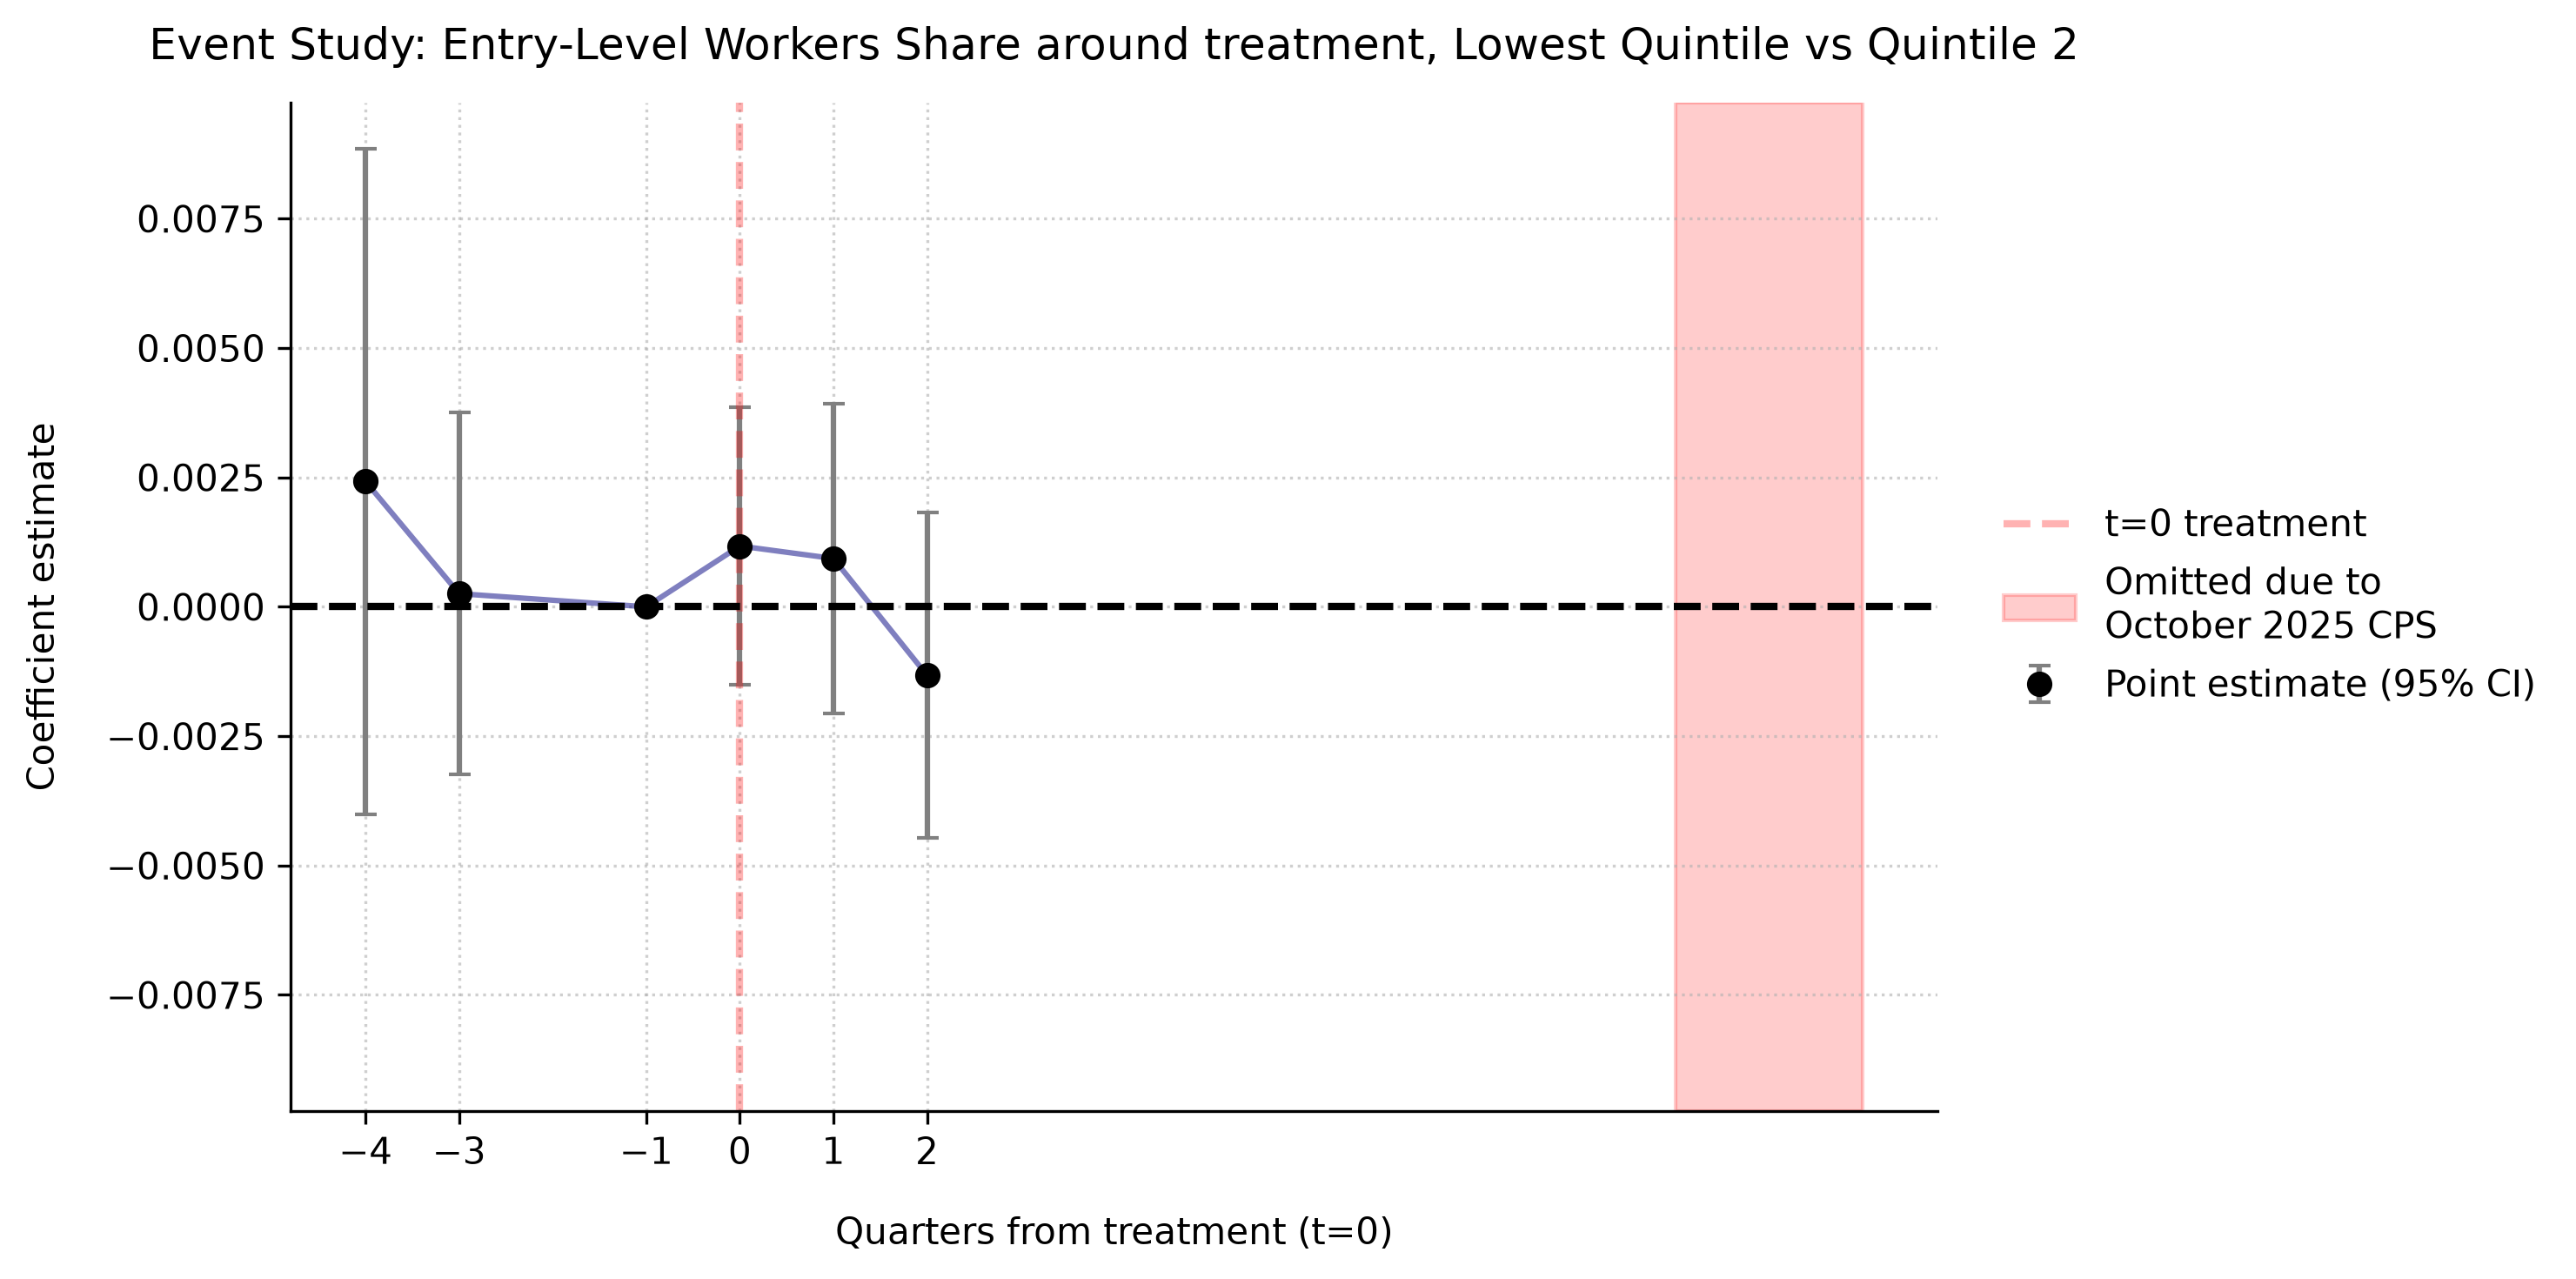

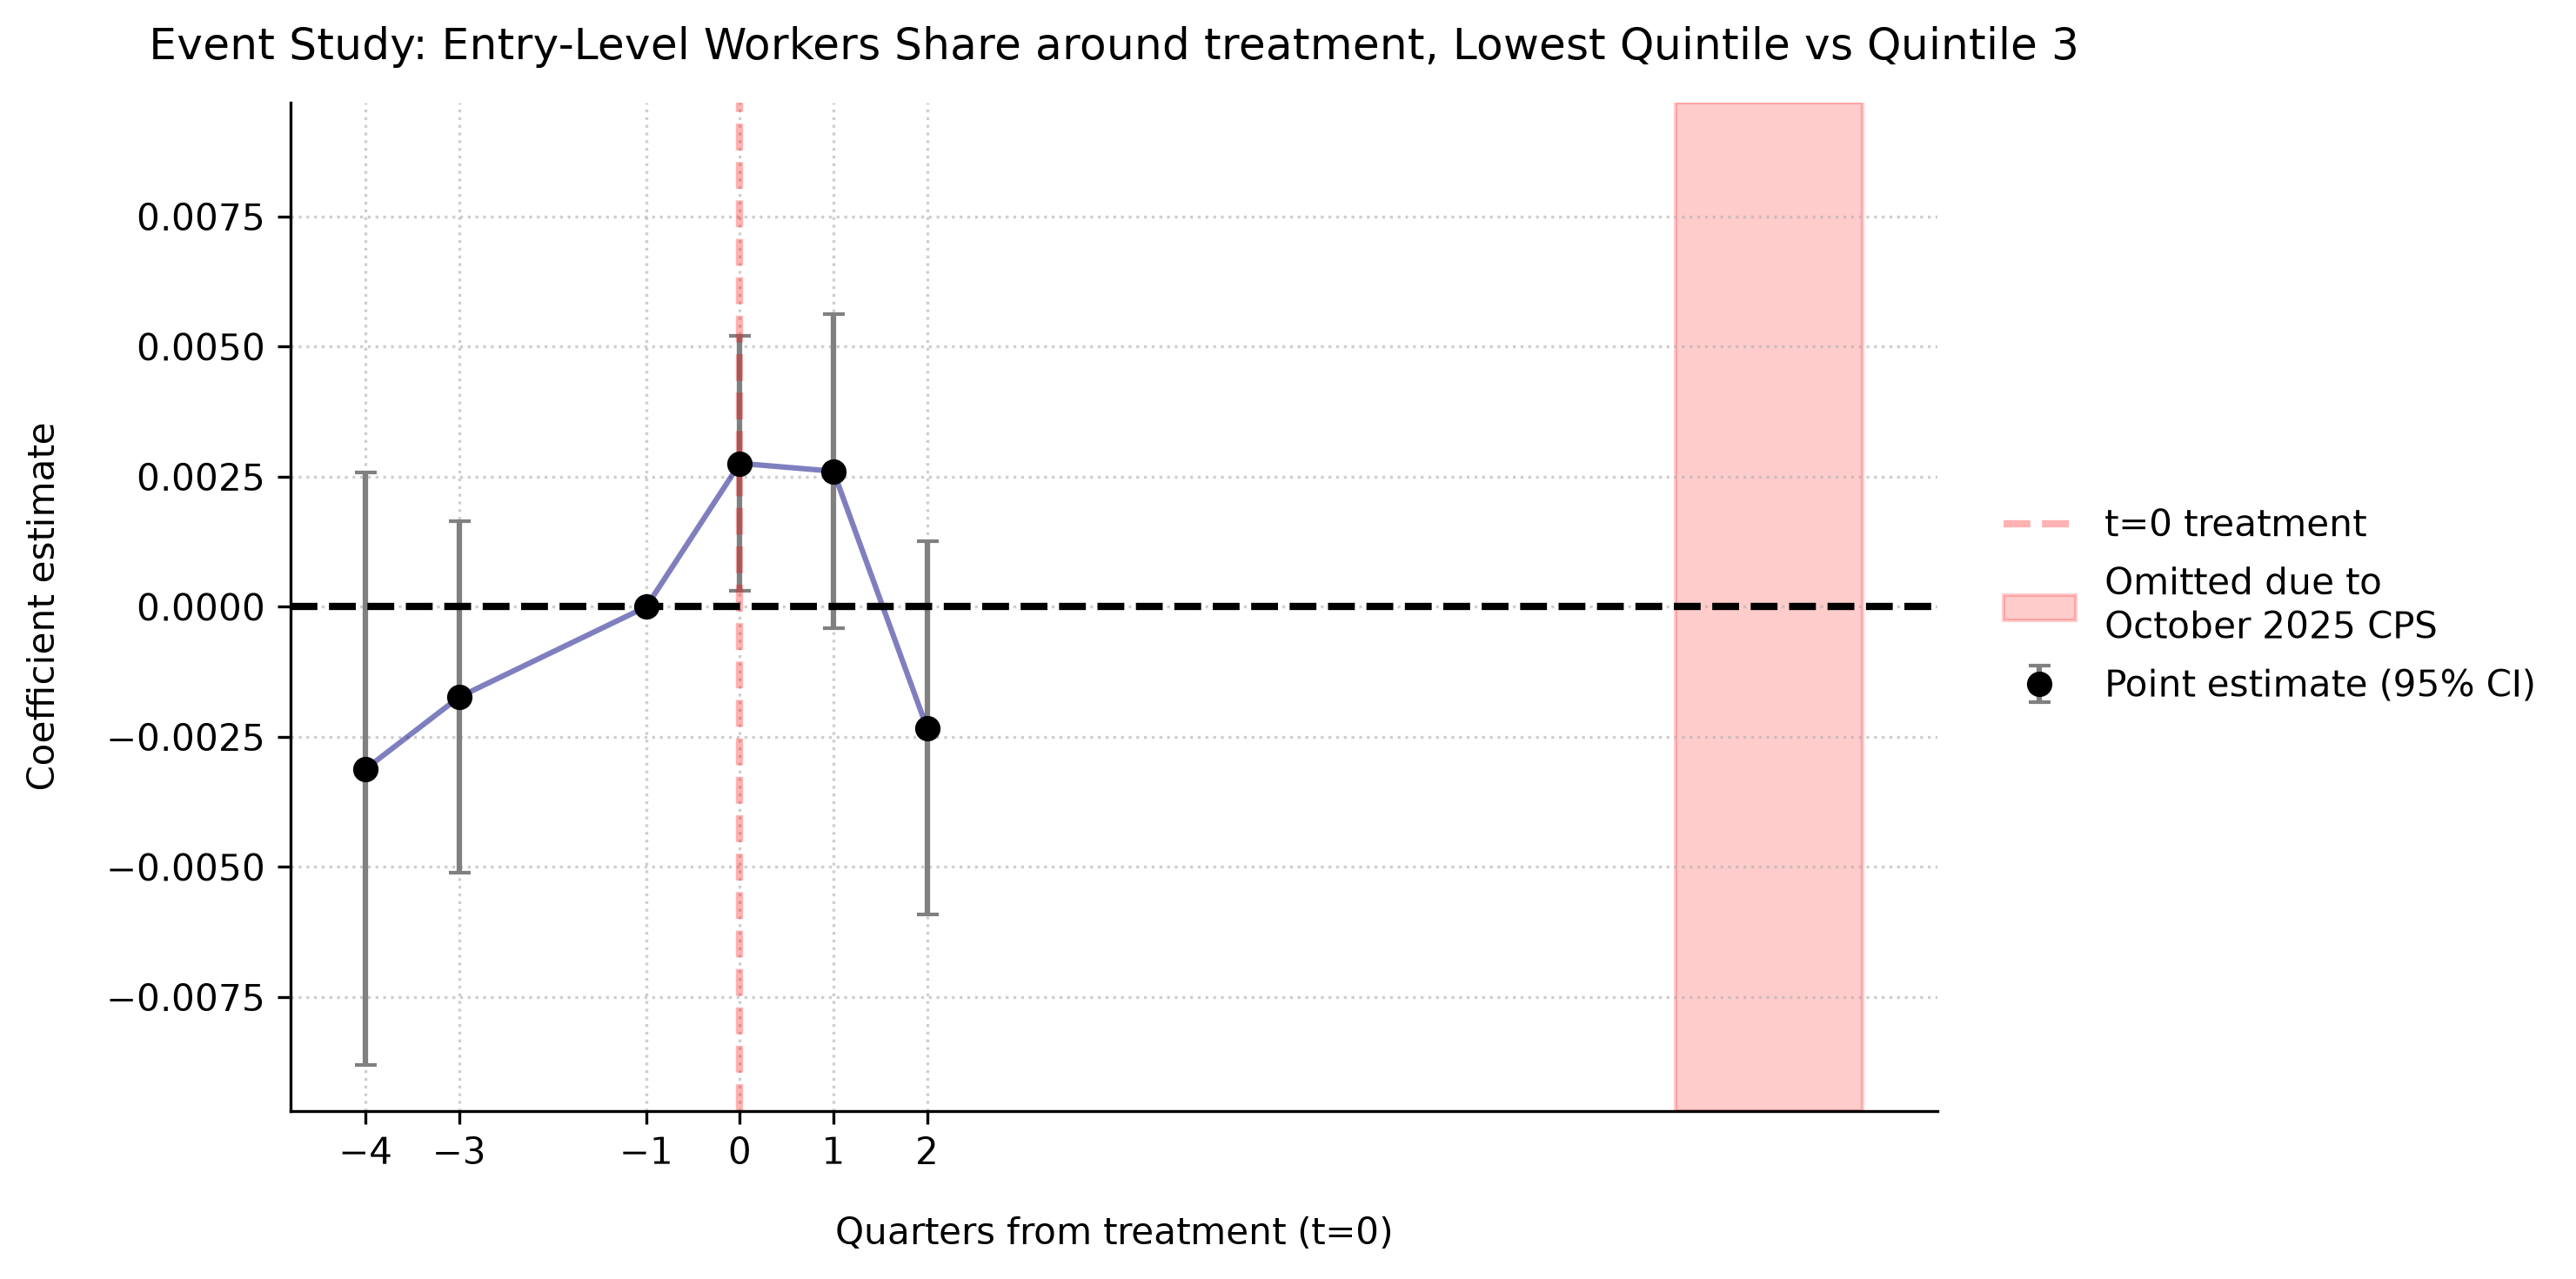

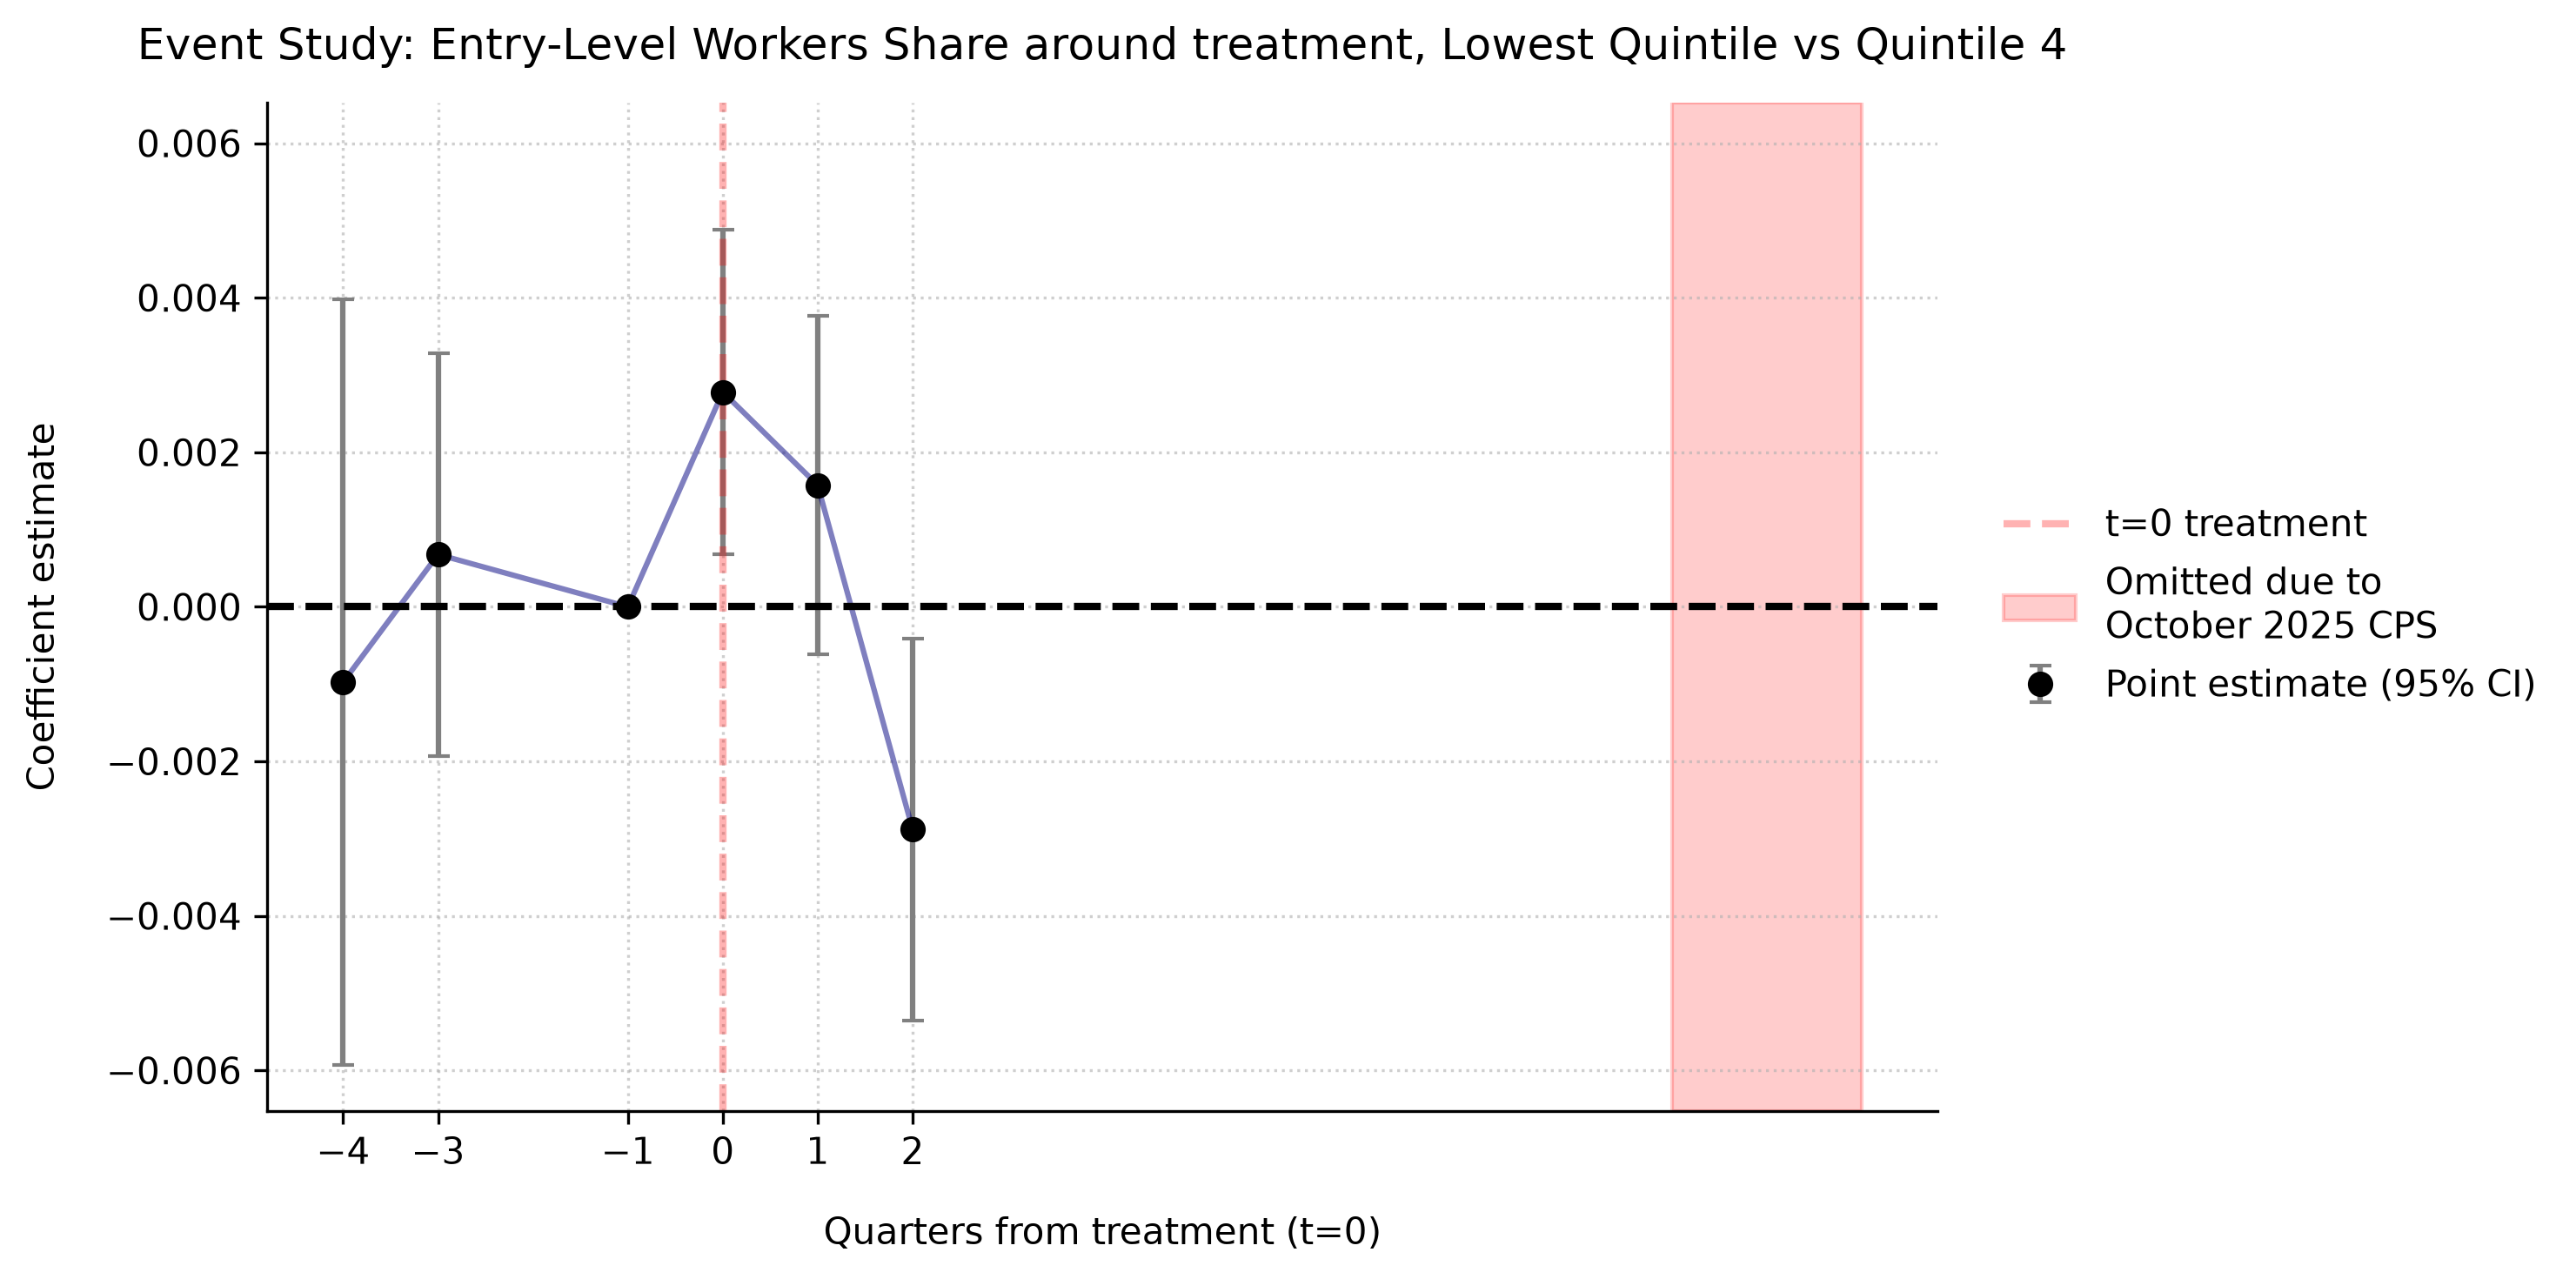

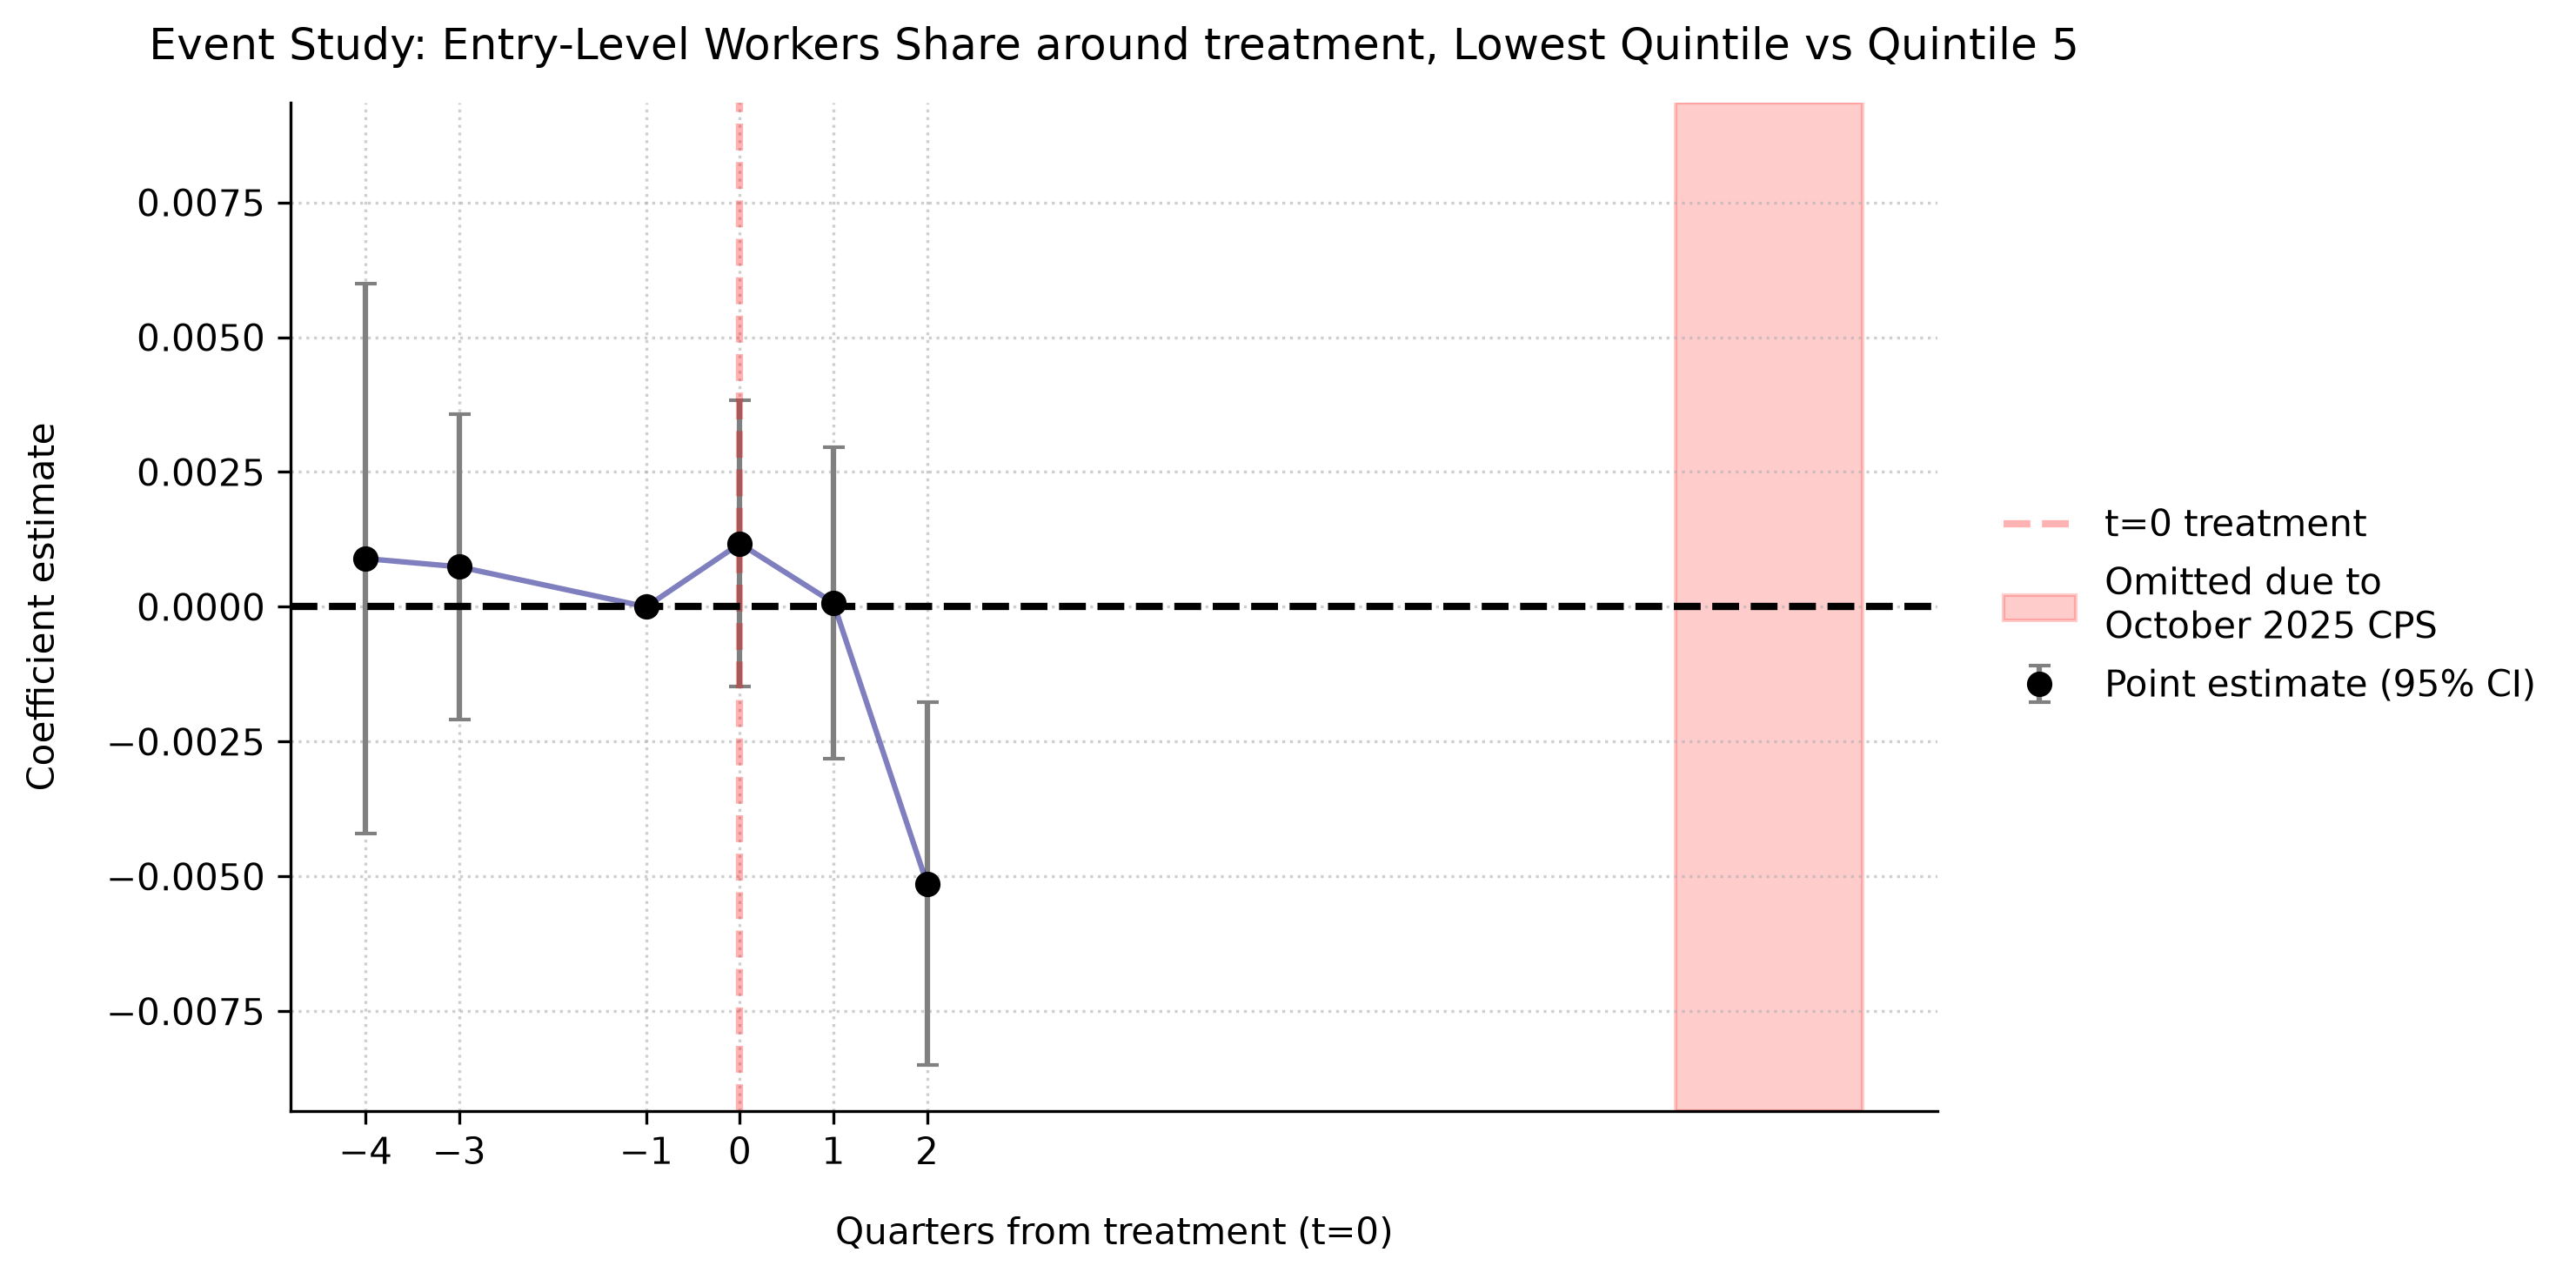

In [84]:
# Event study

quintiles = [2,3,4,5]
REFERENCE_QUINTILE = 1
DV_COL = 'Share_y_22_25'
DV_NAME = 'Entry-Level Workers Share'

for quintile in quintiles:
    df_event = panel.set_index([OCC_COL, 't'], drop=False)
    
    # Filter out unselected quintiles
    df_event = df_event[df_event['beta_q'].isin([REFERENCE_QUINTILE, quintile])]
    
    
     # 1. Generate dummies
    df_event = pd.get_dummies(df_event, columns=['t'], drop_first=False, dtype=int)
    
    # Drop the reference period and create list of dummies
    df_event = df_event.drop(columns=['t_-1'])
    quarter_dummies = [c for c in df_event.columns if str(c).startswith('t_')]

    # Create interaction terms and event study formula
    interaction_terms = ' + '.join([f'Q{quintile}:Q("{d}")' for d in quarter_dummies])
    formula = f"{DV_COL} ~ {interaction_terms} + EntityEffects + TimeEffects"
    print(df_event.columns)
    print(f"EVENT STUDY FORMULA: {formula} {'-'*30}")
    
    # Event study in PANELOLS
    event_study_mod = PanelOLS.from_formula(formula, data=df_event, weights=df_event['N'])
    event_study_res = event_study_mod.fit(cov_type='clustered', cluster_entity=True)
    
    # Save output to tex file
   # dv_slug = DV_NAME.replace(' ', '_')
   ## with open(f"{TABLES_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_reg.tex", "w") as f:
    #    f.write(event_study_res.summary.as_latex())

    df_res = pd.DataFrame({
        'coef': event_study_res.params,
        'lower': event_study_res.conf_int()['lower'],
        'upper': event_study_res.conf_int()['upper']
    })
    
    # Reorganize to reinsert omitted variable
    df_res['quarter'] = df_res['quarter'] = (
        df_res.index
        .str.extract(r"t_(-?\d+)", expand=False)
        .astype(int)
    )
    baseline = pd.DataFrame({'coef': 0.0, 'lower': 0.0, 'upper': 0.0, 'quarter': -1}, index=[-1])
    df_res = pd.concat([df_res, baseline]).sort_values('quarter').reset_index(drop=True)
    
    # Create graph
    fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

    yerr_lower = df_res['coef'] - df_res['lower']
    yerr_upper = df_res['upper'] - df_res['coef']

    ax.errorbar(
        x=df_res['quarter'],
        y=df_res['coef'],
        yerr=np.asanyarray([yerr_lower, yerr_upper]),
        fmt='o',
        color='black',
        ecolor='gray',
        capsize=3,             
        linestyle='None',
        label='Point estimate (95% CI)'
    )

    ax.plot(df_res['quarter'], df_res['coef'], color='navy', alpha=0.5)

    ax.grid(True, linestyle=':', alpha=0.6)

    ax.axvline(x=0, color='r', linestyle='--', linewidth=2, alpha=0.3, label="t=0 treatment")
    ax.axhline(y=0, color='black', linestyle='--', linewidth=2)
    ax.set_xticks(sorted(df_res['quarter'].unique()))

    ax.set_xlabel('Quarters from treatment (t=0)', labelpad=12)
    ax.set_ylabel('Coefficient estimate', labelpad=12)
    ax.set_title(f'Event Study: {DV_NAME} around treatment, Lowest Quintile vs Quintile {quintile}', pad=12)

    y_max = max(df_res['upper'].abs().max(), df_res['lower'].abs().max())
    margin = y_max * 0.1  # 10% padding, adjust to taste
    ax.set_ylim(-(y_max + margin), y_max + margin)
    ax.axvspan(10, 12, color='r', alpha = 0.2, label= "Omitted due to\nOctober 2025 CPS")

    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5))

    plt.tight_layout()
    
    # Save graph
    # fig.savefig(f"{GRAPHS_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_EventStudy.png", dpi=300, bbox_inches='tight')

In [88]:
df_did = panel.set_index(['OCC', 't'], drop=False)
df_did["POST"] = df_did['t'] >= 0

for DV_COL in ['y_18_25', 'y_20_24', 'y_22_25']:
    did_formula = f"{f"Share_{DV_COL}"} ~ POST:Q2 + POST:Q3 + POST:Q4 + POST:Q5 + EntityEffects + TimeEffects"
    did_mod = PanelOLS.from_formula(did_formula, data=df_did, weights=df_did['N'])
    res_did = did_mod.fit(cov_type='clustered', cluster_entity=True)
    print(res_did.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:          Share_y_18_25   R-squared:                        0.0109
Estimator:                   PanelOLS   R-squared (Between):             -0.0016
No. Observations:                3078   R-squared (Within):               0.0095
Date:                Mon, Oct 05 2026   R-squared (Overall):             -0.0016
Time:                        12:48:35   Log-likelihood                    9763.1
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      7.0620
Entities:                         513   P-value                           0.0000
Avg Obs:                       6.0000   Distribution:                  F(4,2556)
Min Obs:                       6.0000                                           
Max Obs:                       6.0000   F-statistic (robust):             1.7089
                            

In [87]:
for DV_COL in ['y_18_25', 'y_20_24', 'y_22_25']:
    print(panel[DV_COL].describe())

count     3078.000000
mean       472.151722
std       1252.168199
min          0.000000
25%         41.000000
50%        109.000000
75%        349.750000
max      16495.000000
Name: y_18_25, dtype: float64
count    3078.000000
mean      294.846654
std       723.329703
min         0.000000
25%        27.000000
50%        73.000000
75%       239.500000
max      8441.000000
Name: y_20_24, dtype: float64
count    3078.000000
mean      236.980182
std       495.127916
min         0.000000
25%        27.000000
50%        70.000000
75%       214.000000
max      4804.000000
Name: y_22_25, dtype: float64
